In [ ]:
# Install PySpark to perform distributed data processing and build machine learning models
!pip install pyspark

In [ ]:
# Upload the used car dataset CSV file to Google Colab for analysis
from google.colab import files

uploaded_files = files.upload()

In [ ]:
# Initialize Spark, load the used cars dataset, and inspect its structure and total number of records
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder \
    .appName("UsedCarPricePrediction") \
    .getOrCreate()

df = spark.read.csv(
    "used_cars.csv",
    header=True,
    inferSchema=True
)

df.show(5)
df.printSchema()

print("Total rows:", df.count())

In [ ]:
# Perform exploratory data analysis to inspect dataset structure, missing values, duplicates, and categorical distributions
# 1. Display first 5 rows
df.show(5, truncate=False)

# 2. Display dataset shape
print("Total rows:", df.count())
print("Total columns:", len(df.columns))

# 3. Display column names
print("Column names:", df.columns)

# 4. Display data types
df.printSchema()

# 5. Summary statistics
df.describe().show()

# 6. Check missing values
from pyspark.sql import functions as F

df.select([
    F.sum(
        F.when(
            F.col(c).isNull() | (F.trim(F.col(c)) == ""),
            1
        ).otherwise(0)
    ).alias(c)
    for c in df.columns
]).show()

# 7. Check duplicate rows
print("Duplicate rows:", df.count() - df.dropDuplicates().count())

# 8. Check unique car brands
df.select("brand").distinct().show(50, truncate=False)

# 9. Count cars by fuel type
df.groupBy("fuel_type").count().orderBy(
    F.desc("count")
).show()

# 10. Count cars by transmission
df.groupBy("transmission").count().orderBy(
    F.desc("count")
).show()

# 11. Check model year distribution
df.groupBy("model_year").count().orderBy(
    F.desc("count")
).show(20)

# 12. Check price distribution (raw values before cleaning)
df.select("price").show(10, truncate=False)

In [24]:
# Clean the used car dataset and preserve all cleaned columns
from pyspark.sql import functions as F

# Load the original dataset
raw_df = spark.read.csv(
    "used_cars.csv",
    header=True,
    inferSchema=False
)

# Remove duplicate records
df = raw_df.dropDuplicates()

# Convert car prices into numeric values by removing currency symbols and commas
df = df.withColumn(
    "price",
    F.regexp_replace("price", r"[$,]", "").cast("double")
)

# Convert mileage strings into numeric values
df = df.withColumn(
    "milage",
    F.regexp_replace("milage", r"[^0-9.]", "").cast("double")
)

# Convert model year into a numeric value
df = df.withColumn(
    "model_year",
    F.col("model_year").cast("double")
)

# Extract engine size in liters from the engine description
# If no match is found, regexp_extract returns empty string, which we cast to null first
df = df.withColumn(
    "engine_size_raw",
    F.regexp_extract("engine", r"(\d+\.?\d*)\s*[Ll]", 1)
)

df = df.withColumn(
    "engine_size",
    F.when(
        F.col("engine_size_raw") != "",
        F.col("engine_size_raw").cast("double")
    ).otherwise(F.lit(None).cast("double"))
).drop("engine_size_raw")

# Remove rows with missing or invalid prices
df = df.filter(
    F.col("price").isNotNull() & (F.col("price") > 0)
)

# Fill missing categorical values using each column's most frequent value
categorical_cols = [
    "brand", "fuel_type", "transmission",
    "accident", "clean_title"
]

for col_name in categorical_cols:
    mode_row = (
        df.filter(
            F.col(col_name).isNotNull() &
            (F.trim(F.col(col_name)) != "")
        )
        .groupBy(col_name)
        .count()
        .orderBy(F.desc("count"), F.asc(col_name))
        .first()
    )

    # Use Unknown if the column has no valid values
    mode_value = mode_row[col_name] if mode_row else "Unknown"

    df = df.withColumn(
        col_name,
        F.when(
            F.col(col_name).isNull() |
            (F.trim(F.col(col_name)) == ""),
            F.lit(mode_value)
        ).otherwise(F.col(col_name))
    )

# Fill missing numerical values using the approximate median
for col_name in ["model_year", "milage", "engine_size"]:
    # Only compute quantiles for non-null values to avoid malformed inputs
    non_null_df = df.filter(F.col(col_name).isNotNull())
    median_values = non_null_df.approxQuantile(
        col_name, [0.5], 0.01
    )

    if median_values:
        df = df.fillna({col_name: median_values[0]})

# Keep the cleaned dataset with all useful original columns
cleaned_df = df.select(
    "brand", "model", "model_year", "milage",
    "fuel_type", "engine", "transmission",
    "ext_col", "int_col", "accident",
    "clean_title", "price", "engine_size"
)

# Preserve compatibility with later cells that use df
df = cleaned_df

# Display the cleaned data and its schema
df.show(5, truncate=False)
df.printSchema()

# Display the total number of cleaned records
print("Total cleaned rows:", cleaned_df.count())

+-------------+--------------------+----------+-------+---------+--------------------------------------------+------------------------------+-------------+-------+--------------------------------------+-----------+--------+-----------+
|brand        |model               |model_year|milage |fuel_type|engine                                      |transmission                  |ext_col      |int_col|accident                              |clean_title|price   |engine_size|
+-------------+--------------------+----------+-------+---------+--------------------------------------------+------------------------------+-------------+-------+--------------------------------------+-----------+--------+-----------+
|Genesis      |G70 2.0T            |2023.0    |2046.0 |Gasoline |252.0HP 2.0L 4 Cylinder Engine Gasoline Fuel|8-Speed A/T                   |Green        |Gray   |None reported                         |Yes        |43499.0 |2.0        |
|Toyota       |Tundra SR           |2018.0    |51000.0|G

In [ ]:
# Calculate car age and visualize correlations between numerical features using a heatmap
from pyspark.sql import functions as F
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Convert model_year to numeric
df = df.withColumn(
    "model_year",
    F.expr("try_cast(model_year AS DOUBLE)")
)

# 2. Calculate car age
df = df.withColumn(
    "car_age",
    F.year(F.current_date()) - F.col("model_year")
)

# 3. Select numerical columns and convert to Pandas
data = df.select(
    "model_year",
    "milage",
    "engine_size",
    "car_age",
    "price"
).toPandas()

# 4. Calculate correlation matrix
correlation = data.corr()

# 5. Plot correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Used Car Price Correlation Heatmap")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F

price_data = df.select(
    F.regexp_replace("price", r"[$,]", "").cast("double").alias("price")
).dropna().toPandas()

plt.figure(figsize=(10, 4))
sns.boxplot(x=price_data["price"])
plt.show()

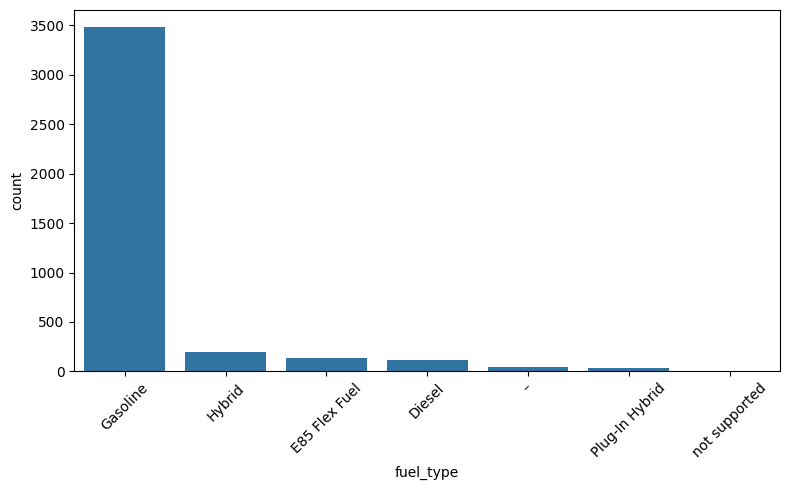

In [25]:

# Visualize the number of used cars in each fuel type category
import matplotlib.pyplot as plt
import seaborn as sns

# Count cars in each fuel type using the cleaned dataset
fuel_data = (
    cleaned_df.groupBy("fuel_type")
    .count()
    .orderBy("count", ascending=False)
    .toPandas()
)

# Create a bar chart to compare fuel type categories
plt.figure(figsize=(8, 5))
sns.barplot(data=fuel_data, x="fuel_type", y="count")

# Format the chart
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
# Use Spark SQL to calculate and display average car prices for each brand in descending order
df.createOrReplaceTempView("used_cars")

spark.sql("""
    SELECT brand, AVG(price) AS average_price
    FROM used_cars
    GROUP BY brand
    ORDER BY average_price DESC
""").show()

In [ ]:
# Use Spark SQL to display the 10 most expensive cars along with their brands and model years
df.createOrReplaceTempView("used_cars")

spark.sql("""
    SELECT brand, model_year, price
    FROM used_cars
    WHERE price IS NOT NULL
    ORDER BY price DESC
    LIMIT 10
""").show()

In [26]:

# Prepare numerical features for used car price prediction
from pyspark.sql import functions as F

# Select the features and target required for the regression models
model_df = cleaned_df.select(
    "model_year",
    "milage",
    "engine_size",
    "price"
)

# Ensure all selected columns use numeric data types
for col_name in [
    "model_year", "milage", "engine_size", "price"
]:
    model_df = model_df.withColumn(
        col_name,
        F.col(col_name).cast("double")
    )

# Remove records with missing required values and duplicates
model_df = model_df.dropna(
    subset=["model_year", "milage", "engine_size", "price"]
).dropDuplicates()

# Remove invalid prices, negative mileage and invalid engine sizes
model_df = model_df.filter(
    (F.col("price") > 0) &
    (F.col("milage") >= 0) &
    (F.col("engine_size") > 0)
)

# Display the prepared dataset
model_df.show(5)
print("Rows available for training:", model_df.count())

# Split the data into 80% training and 20% testing
train_data, test_data = model_df.randomSplit(
    [0.8, 0.2],
    seed=42
)

# Display the size of each dataset
print("Training rows:", train_data.count())
print("Testing rows:", test_data.count())


+----------+--------+-----------+-------+
|model_year|  milage|engine_size|  price|
+----------+--------+-----------+-------+
|    2011.0|170000.0|        3.6| 4000.0|
|    2019.0| 53677.0|        5.6|27900.0|
|    2022.0| 14550.0|        2.0|41500.0|
|    2017.0| 37375.0|        3.0|27500.0|
|    2013.0|134000.0|        5.4|21500.0|
+----------+--------+-----------+-------+
only showing top 5 rows
Rows available for training: 4009
Training rows: 3266
Testing rows: 743


In [27]:

# Train a Linear Regression model and evaluate its predictions
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

# Combine the numerical input columns into a single feature vector
model_assembler = VectorAssembler(
    inputCols=["model_year", "milage", "engine_size"],
    outputCol="features",
    handleInvalid="skip"
)

# Transform the training and testing datasets
train_features = model_assembler.transform(train_data)
test_features = model_assembler.transform(test_data)

# Create the Linear Regression model
lr = LinearRegression(
    featuresCol="features",
    labelCol="price"
)

# Train the model using the training dataset
lr_model = lr.fit(train_features)

# Predict car prices for the testing dataset
lr_predictions = lr_model.transform(test_features)

# Display actual and predicted prices
lr_predictions.select(
    "price", "prediction"
).show(10)

# Evaluate the model using R2, RMSE and MAE
for metric in ["r2", "rmse", "mae"]:
    evaluator = RegressionEvaluator(
        labelCol="price",
        predictionCol="prediction",
        metricName=metric
    )

    print(
        metric.upper(), ":",
        round(evaluator.evaluate(lr_predictions), 3)
    )


+-------+-------------------+
|  price|         prediction|
+-------+-------------------+
| 9599.0|  21931.62180809956|
|15300.0|  2708.395920508774|
| 4200.0| -2762.386314614443|
| 7900.0| 12494.178338007303|
|19000.0| 19483.498391999165|
|15000.0|  -30574.8999236722|
|15500.0|-15772.465060570277|
| 8500.0|-14445.414155288134|
| 5500.0|-15858.060333653586|
|11500.0| 20437.770263285143|
+-------+-------------------+
only showing top 10 rows
R2 : 0.052
RMSE : 130949.51
MAE : 26645.22


In [28]:

# Train a Decision Tree Regression model to predict used car prices
from pyspark.ml.regression import DecisionTreeRegressor

# Configure the Decision Tree model
dt = DecisionTreeRegressor(
    featuresCol="features",
    labelCol="price",
    maxDepth=5
)

# Train the model using the prepared training features
dt_model = dt.fit(train_features)

# Generate predictions using the prepared testing features
dt_predictions = dt_model.transform(test_features)

# Display actual and predicted car prices
dt_predictions.select(
    "price", "prediction"
).show(10)


+-------+------------------+
|  price|        prediction|
+-------+------------------+
| 9599.0|25459.092307692306|
|15300.0|12134.473154362417|
| 4200.0|12134.473154362417|
| 7900.0|25459.092307692306|
|19000.0|25459.092307692306|
|15000.0|12134.473154362417|
|15500.0|12134.473154362417|
| 8500.0|12134.473154362417|
| 5500.0|12134.473154362417|
|11500.0|12134.473154362417|
+-------+------------------+
only showing top 10 rows


In [ ]:
# Compare Linear Regression and Decision Tree models using R², RMSE, and MAE evaluation metrics
from pyspark.ml.evaluation import RegressionEvaluator

# Create evaluators
rmse_evaluator = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="rmse"
)

mae_evaluator = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="mae"
)

r2_evaluator = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="r2"
)

# Evaluate Linear Regression
print("Linear Regression Results")
print("R2:", r2_evaluator.evaluate(lr_predictions))
print("RMSE:", rmse_evaluator.evaluate(lr_predictions))
print("MAE:", mae_evaluator.evaluate(lr_predictions))

# Evaluate Decision Tree
print("\nDecision Tree Regression Results")
print("R2:", r2_evaluator.evaluate(dt_predictions))
print("RMSE:", rmse_evaluator.evaluate(dt_predictions))
print("MAE:", mae_evaluator.evaluate(dt_predictions))

In [29]:

# Prepare and scale numerical features for K-Means clustering
from pyspark.ml.feature import VectorAssembler, StandardScaler

# Select numerical attributes for grouping similar cars
cluster_data = cleaned_df.select(
    "model_year",
    "milage",
    "engine_size",
    "price"
)

# Remove records with missing values in clustering features
cluster_data = cluster_data.dropna(
    subset=["model_year", "milage", "engine_size", "price"]
)

# Combine numerical attributes into a feature vector
cluster_assembler = VectorAssembler(
    inputCols=["model_year", "milage", "engine_size", "price"],
    outputCol="raw_features",
    handleInvalid="skip"
)

assembled_cluster_data = cluster_assembler.transform(cluster_data)

# Standardize features so different measurement scales do not dominate clustering
scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features",
    withMean=True,
    withStd=True
)

# Fit the scaler and transform the data
scaler_model = scaler.fit(assembled_cluster_data)
scaled_data = scaler_model.transform(assembled_cluster_data)

# Display the scaled features and original prices
scaled_data.select(
    "price", "features"
).show(5, truncate=False)


+--------+---------------------------------------------------------------------------------+
|price   |features                                                                         |
+--------+---------------------------------------------------------------------------------+
|43499.0 |[1.225984498307937,-1.198386733707797,-1.2140817524887288,-0.013393238592901247] |
|38000.0 |[0.40695902693388786,-0.2623029250853109,1.468619423475813,-0.08325673240517845] |
|42000.0 |[0.5707641212086977,-0.4224280591582099,1.976157483793429,-0.03243767889561147]  |
|229000.0|[1.0621794040331272,-1.1464904339855797,0.23602699127588822,2.3433530726766443]  |
|34900.0 |[-0.41206644444016144,0.6443143404745603,0.8160704887817349,-0.12264149887509285]|
+--------+---------------------------------------------------------------------------------+
only showing top 5 rows


In [30]:
# Apply K-Means clustering to group similar used cars

from pyspark.ml.clustering import KMeans

# Create a K-Means model with 3 clusters
kmeans = KMeans(k=3, seed=42, featuresCol="features")

# Train the model
model = kmeans.fit(scaled_data)

# Assign each car to a cluster
predictions = model.transform(scaled_data)

# Display car prices and their cluster numbers
predictions.select("price", "prediction").show(10)

# Count cars in each cluster
predictions.groupBy("prediction").count().show()

+--------+----------+
|   price|prediction|
+--------+----------+
| 43499.0|         0|
| 38000.0|         1|
| 42000.0|         1|
|229000.0|         1|
| 34900.0|         2|
| 20500.0|         0|
| 51500.0|         1|
| 77900.0|         0|
| 30989.0|         0|
| 67000.0|         0|
+--------+----------+
only showing top 10 rows
+----------+-----+
|prediction|count|
+----------+-----+
|         1|  846|
|         2| 1229|
|         0| 1934|
+----------+-----+

